In [2]:
import joblib
import pandas as pd
import numpy as np

# Load trained model
model = joblib.load("../models/random_forest_pipeline.joblib")

# Load original dataset
df = pd.read_csv("../data/raw/KAG_conversion_data.csv")

# Select features
features = [
    "age",
    "gender",
    "interest",
    "xyz_campaign_id",
    "Impressions",
    "Spent"
]

target = "Total_Conversion"

X = df[features]
y = df[target]

# Recreate the same test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Explainable AI Model Loaded!")
print("Model:", type(model).__name__)
print("Test Data Shape:", X_test.shape)
print("Target Shape:", y_test.shape)

Explainable AI Model Loaded!
Model: Pipeline
Test Data Shape: (229, 6)
Target Shape: (229,)


In [3]:
# Generate predictions
predictions = model.predict(X_test)

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    "Actual Conversion": y_test.values,
    "Predicted Conversion": predictions
})

print("Predictions Generated Successfully!")
print("\nFirst 10 Predictions:")
print(comparison_df.head(10).round(2))

print("\nPrediction Shape:", predictions.shape)

Predictions Generated Successfully!

First 10 Predictions:
   Actual Conversion  Predicted Conversion
0                  1                  1.03
1                  2                  1.88
2                  3                  1.08
3                  1                  1.85
4                  1                  1.03
5                  3                  4.46
6                  1                  1.14
7                  1                  1.11
8                  1                  1.03
9                  1                  1.05

Prediction Shape: (229,)


In [4]:
# Extract preprocessing pipeline
preprocessor = model.named_steps["preprocessor"]

# Transform test data
X_test_transformed = preprocessor.transform(X_test)

# Convert sparse matrix to dense array
if hasattr(X_test_transformed, "toarray"):
    X_test_numeric = X_test_transformed.toarray()
else:
    X_test_numeric = X_test_transformed

X_test_numeric = X_test_numeric.astype(np.float64)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Test Data Transformation Successful!")
print("Transformed Data Shape:", X_test_numeric.shape)
print("Feature Names Count:", len(feature_names))
print("Data Type:", X_test_numeric.dtype)

Test Data Transformation Successful!
Transformed Data Shape: (229, 51)
Feature Names Count: 51
Data Type: float64


In [5]:
# Extract trained Random Forest estimator
rf_model = model.named_steps["regressor"]

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_values = explainer.shap_values(
    X_test_numeric,
    check_additivity=False
)

print("SHAP Explainer Created Successfully!")
print("SHAP Values Shape:", np.array(shap_values).shape)
print("Input Features Shape:", X_test_numeric.shape)

SHAP Explainer Created Successfully!
SHAP Values Shape: (229, 51)
Input Features Shape: (229, 51)


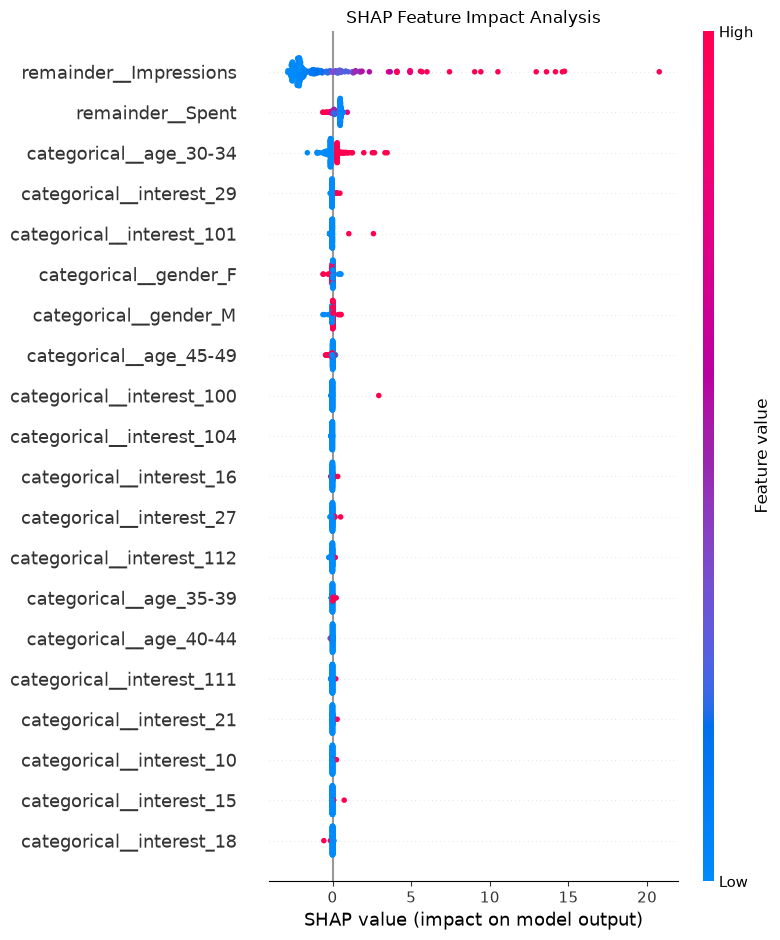

In [6]:
shap.summary_plot(
    shap_values,
    X_test_numeric,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Feature Impact Analysis")
plt.tight_layout()
plt.show()

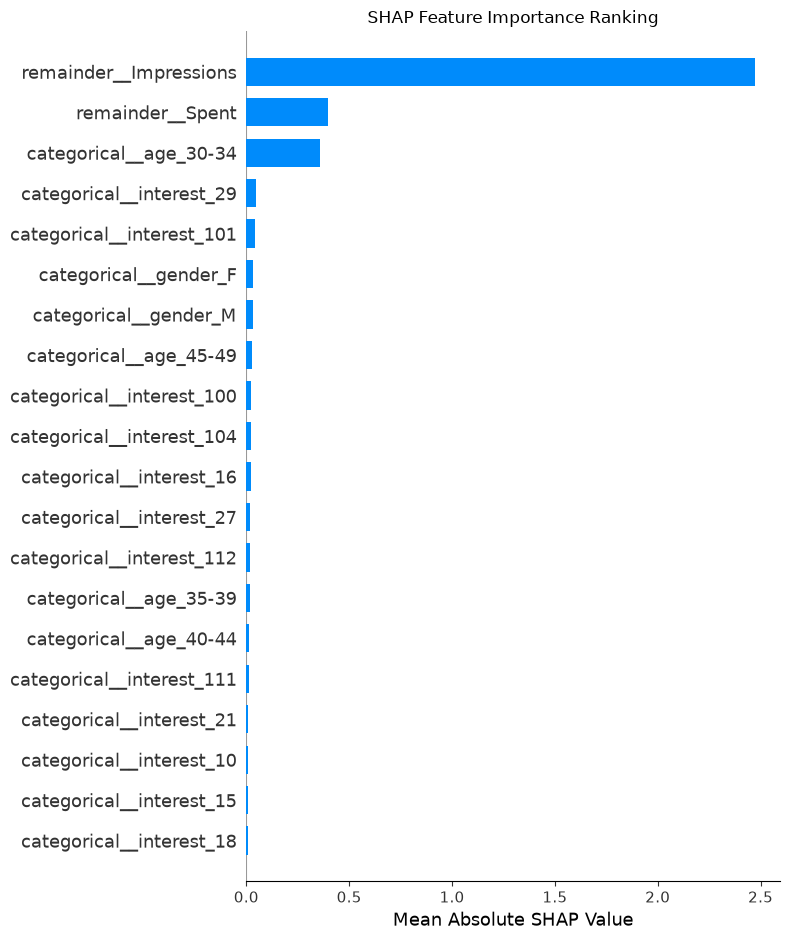

In [7]:
# SHAP Feature Importance Bar Plot

shap.summary_plot(
    shap_values,
    X_test_numeric,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance Ranking")
plt.xlabel("Mean Absolute SHAP Value")
plt.tight_layout()
plt.show()